In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

DATA = ROOT / "ml" / "processed"
MODEL_DIR = ROOT / "ml" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

config = json.load(open(DATA / "preprocess_config.json"))
df = pd.read_csv(DATA / "dataset_splits.csv")

IMG_SIZE = tuple(config["img_size"])
THRESHOLD = config["mask_threshold"]
MEAN = np.array(config["mean"], dtype=np.float32)
STD = np.array(config["std"], dtype=np.float32)

print("Project root:", ROOT)
print(df["split"].value_counts())


Project root: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
split
train    6455
test      808
val       807
Name: count, dtype: int64


In [3]:
train_df = df[df.split == "train"].reset_index(drop=True)
val_df = df[df.split == "val"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 6455
Validation: 807
Test: 808


In [4]:

def load_data(dataframe):
    X, Y = [], []

    for _, row in dataframe.iterrows():
        img = Image.open(ROOT / row.image_path).convert("RGB")
        img = img.resize(IMG_SIZE)
        img = np.array(img, dtype=np.float32) / 255.0
        img = (img - MEAN) / STD

        mask = Image.open(ROOT / row.mask_path).convert("L")
        mask = mask.resize(IMG_SIZE, Image.Resampling.NEAREST)
        mask = (np.array(mask) > THRESHOLD).astype("float32")

        X.append(img)
        Y.append(mask[..., None])

    return np.array(X, dtype="float32"), np.array(Y, dtype="float32")


# Load datasets
X_train, Y_train = load_data(train_df)
X_val, Y_val = load_data(val_df)
X_test, Y_test = load_data(test_df)


# Print dataset information
print("Train images:", X_train.shape)
print("Train masks:", Y_train.shape)

print("Validation images:", X_val.shape)
print("Validation masks:", Y_val.shape)

print("Test images:", X_test.shape)
print("Test masks:", Y_test.shape)


# Check memory usage
print("\nData type:", X_train.dtype)
print("Training memory:", X_train.nbytes / (1024**3), "GB")
print("Validation memory:", X_val.nbytes / (1024**3), "GB")
print("Test memory:", X_test.nbytes / (1024**3), "GB")


Train images: (6455, 256, 256, 3)
Train masks: (6455, 256, 256, 1)
Validation images: (807, 256, 256, 3)
Validation masks: (807, 256, 256, 1)
Test images: (808, 256, 256, 3)
Test masks: (808, 256, 256, 1)

Data type: float32
Training memory: 4.727783203125 GB
Validation memory: 0.591064453125 GB
Test memory: 0.591796875 GB


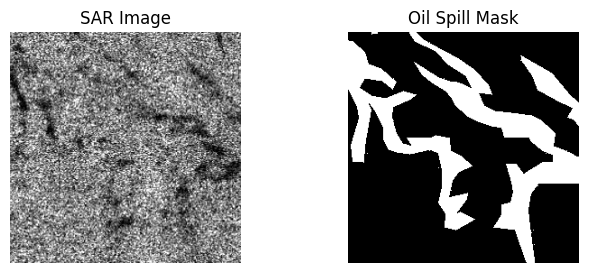

In [5]:
plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.imshow(np.clip(X_train[0] * STD + MEAN, 0, 1))
plt.title("SAR Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(Y_train[0, :, :, 0], cmap="gray")
plt.title("Oil Spill Mask")
plt.axis("off")

plt.show()

In [6]:
def dice_score(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2 * intersection + 1e-6) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + 1e-6
    )


def loss_fn(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )
    return bce + (1 - dice_score(y_true, y_pred))

In [7]:
def block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return x


def build_unet():
    inputs = layers.Input((IMG_SIZE[1], IMG_SIZE[0], 3))

    c1 = block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    middle = block(p4, 256)

    u4 = layers.Conv2DTranspose(128, 2, strides=2, padding="same")(middle)
    u4 = layers.Concatenate()([u4, c4])
    c5 = block(u4, 128)

    u3 = layers.Conv2DTranspose(64, 2, strides=2, padding="same")(c5)
    u3 = layers.Concatenate()([u3, c3])
    c6 = block(u3, 64)

    u2 = layers.Conv2DTranspose(32, 2, strides=2, padding="same")(c6)
    u2 = layers.Concatenate()([u2, c2])
    c7 = block(u2, 32)

    u1 = layers.Conv2DTranspose(16, 2, strides=2, padding="same")(c7)
    u1 = layers.Concatenate()([u1, c1])
    c8 = block(u1, 16)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(c8)
    return Model(inputs, outputs)


model = build_unet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    131,200 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 1,941,105 (7.40 MB)

 Trainable params: 1,941,105 (7.40 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=loss_fn,
    metrics=[dice_score]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_DIR / "best_unet.keras",
        save_best_only=True,
        monitor="val_dice_score",
        mode="max"
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_score",
        patience=5,
        mode="max",
        restore_best_weights=True
    )
]

In [9]:
history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=20,
    batch_size=2,
    callbacks=callbacks
)

Epoch 1/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 250s 75ms/step - dice_score: 0.6764 - loss: 0.6160 - val_dice_score: 0.6938 - val_loss: 0.5948
Epoch 2/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 230s 71ms/step - dice_score: 0.7169 - loss: 0.5404 - val_dice_score: 0.7037 - val_loss: 0.5840
Epoch 3/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 231s 71ms/step - dice_score: 0.7272 - loss: 0.5216 - val_dice_score: 0.7062 - val_loss: 0.5793
Epoch 4/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 237s 73ms/step - dice_score: 0.7342 - loss: 0.5085 - val_dice_score: 0.7130 - val_loss: 0.5703
Epoch 5/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 235s 73ms/step - dice_score: 0.7390 - loss: 0.4996 - val_dice_score: 0.7234 - val_loss: 0.5479
Epoch 6/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 235s 73ms/step - dice_score: 0.7410 - loss: 0.4959 - val_dice_score: 0.7339 - val_loss: 0.5433
Epoch 7/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━ 234s 73ms/step - dice_score: 0.7451 - loss: 0.4882 - val_dice_score: 0.7342 - val_loss: 0.5378
Epoch 8/20
3228/3228 ━━━━━━━━━━━━━━━━━━━━

In [10]:
# Load the best saved model
best_model = tf.keras.models.load_model(
    MODEL_DIR / "best_unet.keras",
    custom_objects={"loss_fn": loss_fn, "dice_score": dice_score}
)

pred = best_model.predict(X_test, batch_size=8)
pred_mask = (pred > 0.5).astype("uint8")
true_mask = (Y_test > 0.5).astype("uint8")

def get_scores(y_true, y_pred):
    intersection = np.logical_and(y_true, y_pred).sum()
    union = np.logical_or(y_true, y_pred).sum()
    dice = (2 * intersection) / (y_true.sum() + y_pred.sum() + 1e-7)
    iou = intersection / (union + 1e-7)
    precision = intersection / (y_pred.sum() + 1e-7)
    recall = intersection / (y_true.sum() + 1e-7)
    return dice, iou, precision, recall

scores = get_scores(true_mask, pred_mask)
print("Dice:", round(scores[0], 4))
print("IoU:", round(scores[1], 4))
print("Precision:", round(scores[2], 4))
print("Recall:", round(scores[3], 4))

101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step
Dice: 0.8238
IoU: 0.7005
Precision: 0.7837
Recall: 0.8683


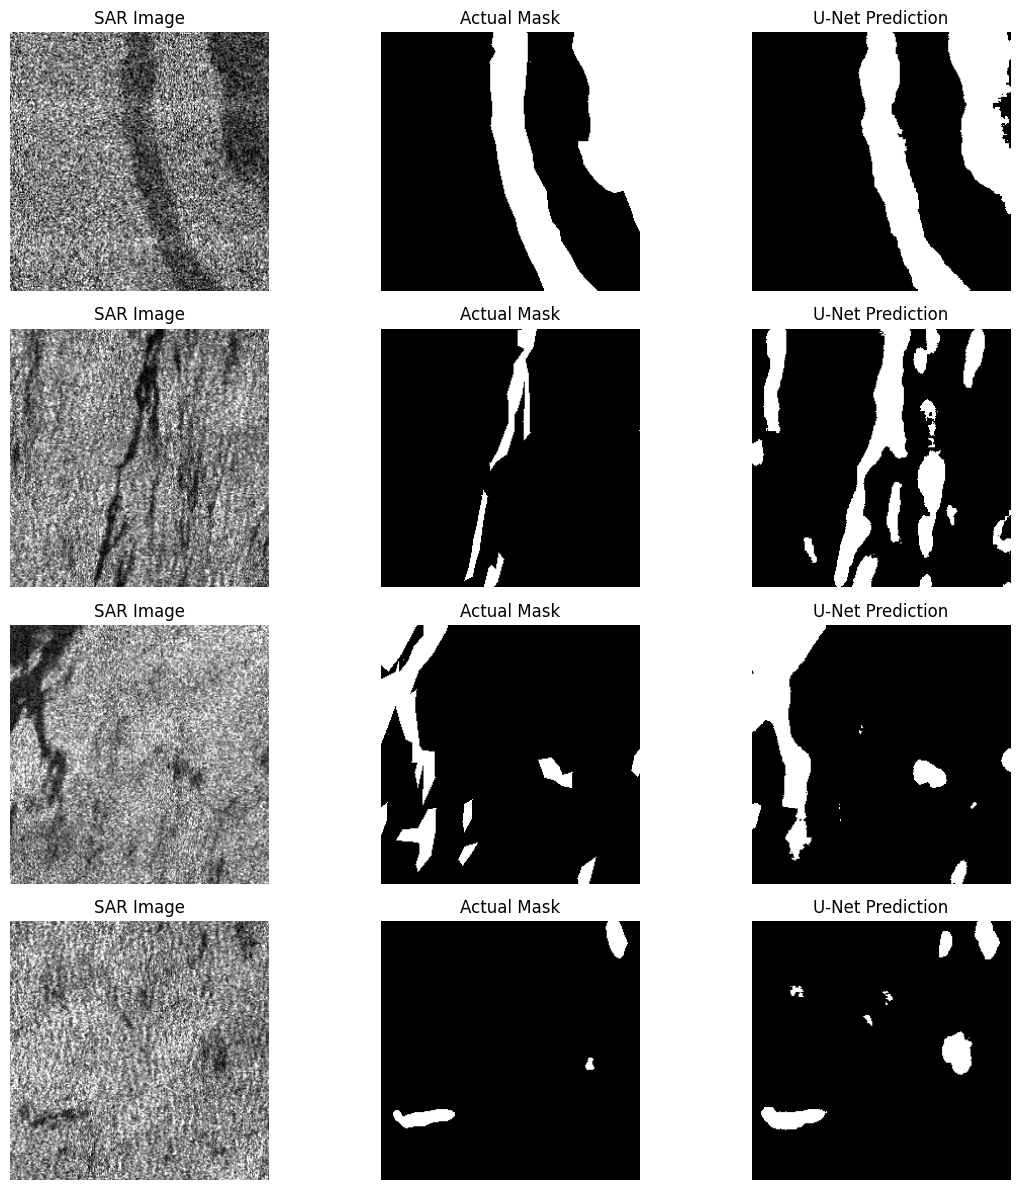

In [11]:
n = min(4, len(X_test))
plt.figure(figsize=(12, 3 * n))

for i in range(n):
    plt.subplot(n, 3, i * 3 + 1)
    plt.imshow(np.clip(X_test[i] * STD + MEAN, 0, 1))
    plt.title("SAR Image")
    plt.axis("off")

    plt.subplot(n, 3, i * 3 + 2)
    plt.imshow(true_mask[i, :, :, 0], cmap="gray")
    plt.title("Actual Mask")
    plt.axis("off")

    plt.subplot(n, 3, i * 3 + 3)
    plt.imshow(pred_mask[i, :, :, 0], cmap="gray")
    plt.title("U-Net Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
best_model.save(MODEL_DIR / "final_unet.keras")

results = pd.DataFrame([{
    "Dice": scores[0],
    "IoU": scores[1],
    "Precision": scores[2],
    "Recall": scores[3]
}])

results.to_csv(ROOT / "ml" / "results" / "unet_results.csv", index=False)
print(results)
print("U-Net model and results saved.")

       Dice       IoU  Precision    Recall
0  0.823843  0.700453   0.783693  0.868329
U-Net model and results saved.
